#Deep Learning para visión de computadoras
##Lab 3.3 GAN condicional, FID y aumento con datos sintéticos

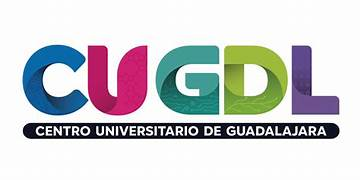

# Explica que es la aumentacion de datos coloca una imagen que lo ejemplifique y menciona cuales son las ventajas de aplicarlo en tu proyecto

[Aumento de datos con Ultralytics YOLO](https://docs.ultralytics.com/es/guides/yolo-data-augmentation)

La aumentacion de datos consiste en crear artificialmente nuevas muestras de entrenamiento a partir de las que ya tienes, aplicando transformaciones ligeras y aleatorias que no cambian el significado original de la imagen.

En mi proyecto puede funcionar para hacer al modelo más robusto a condiciones reales. Y tambien porque puedeb ser necesario tener mas imagenes para desarrollar el proyecto

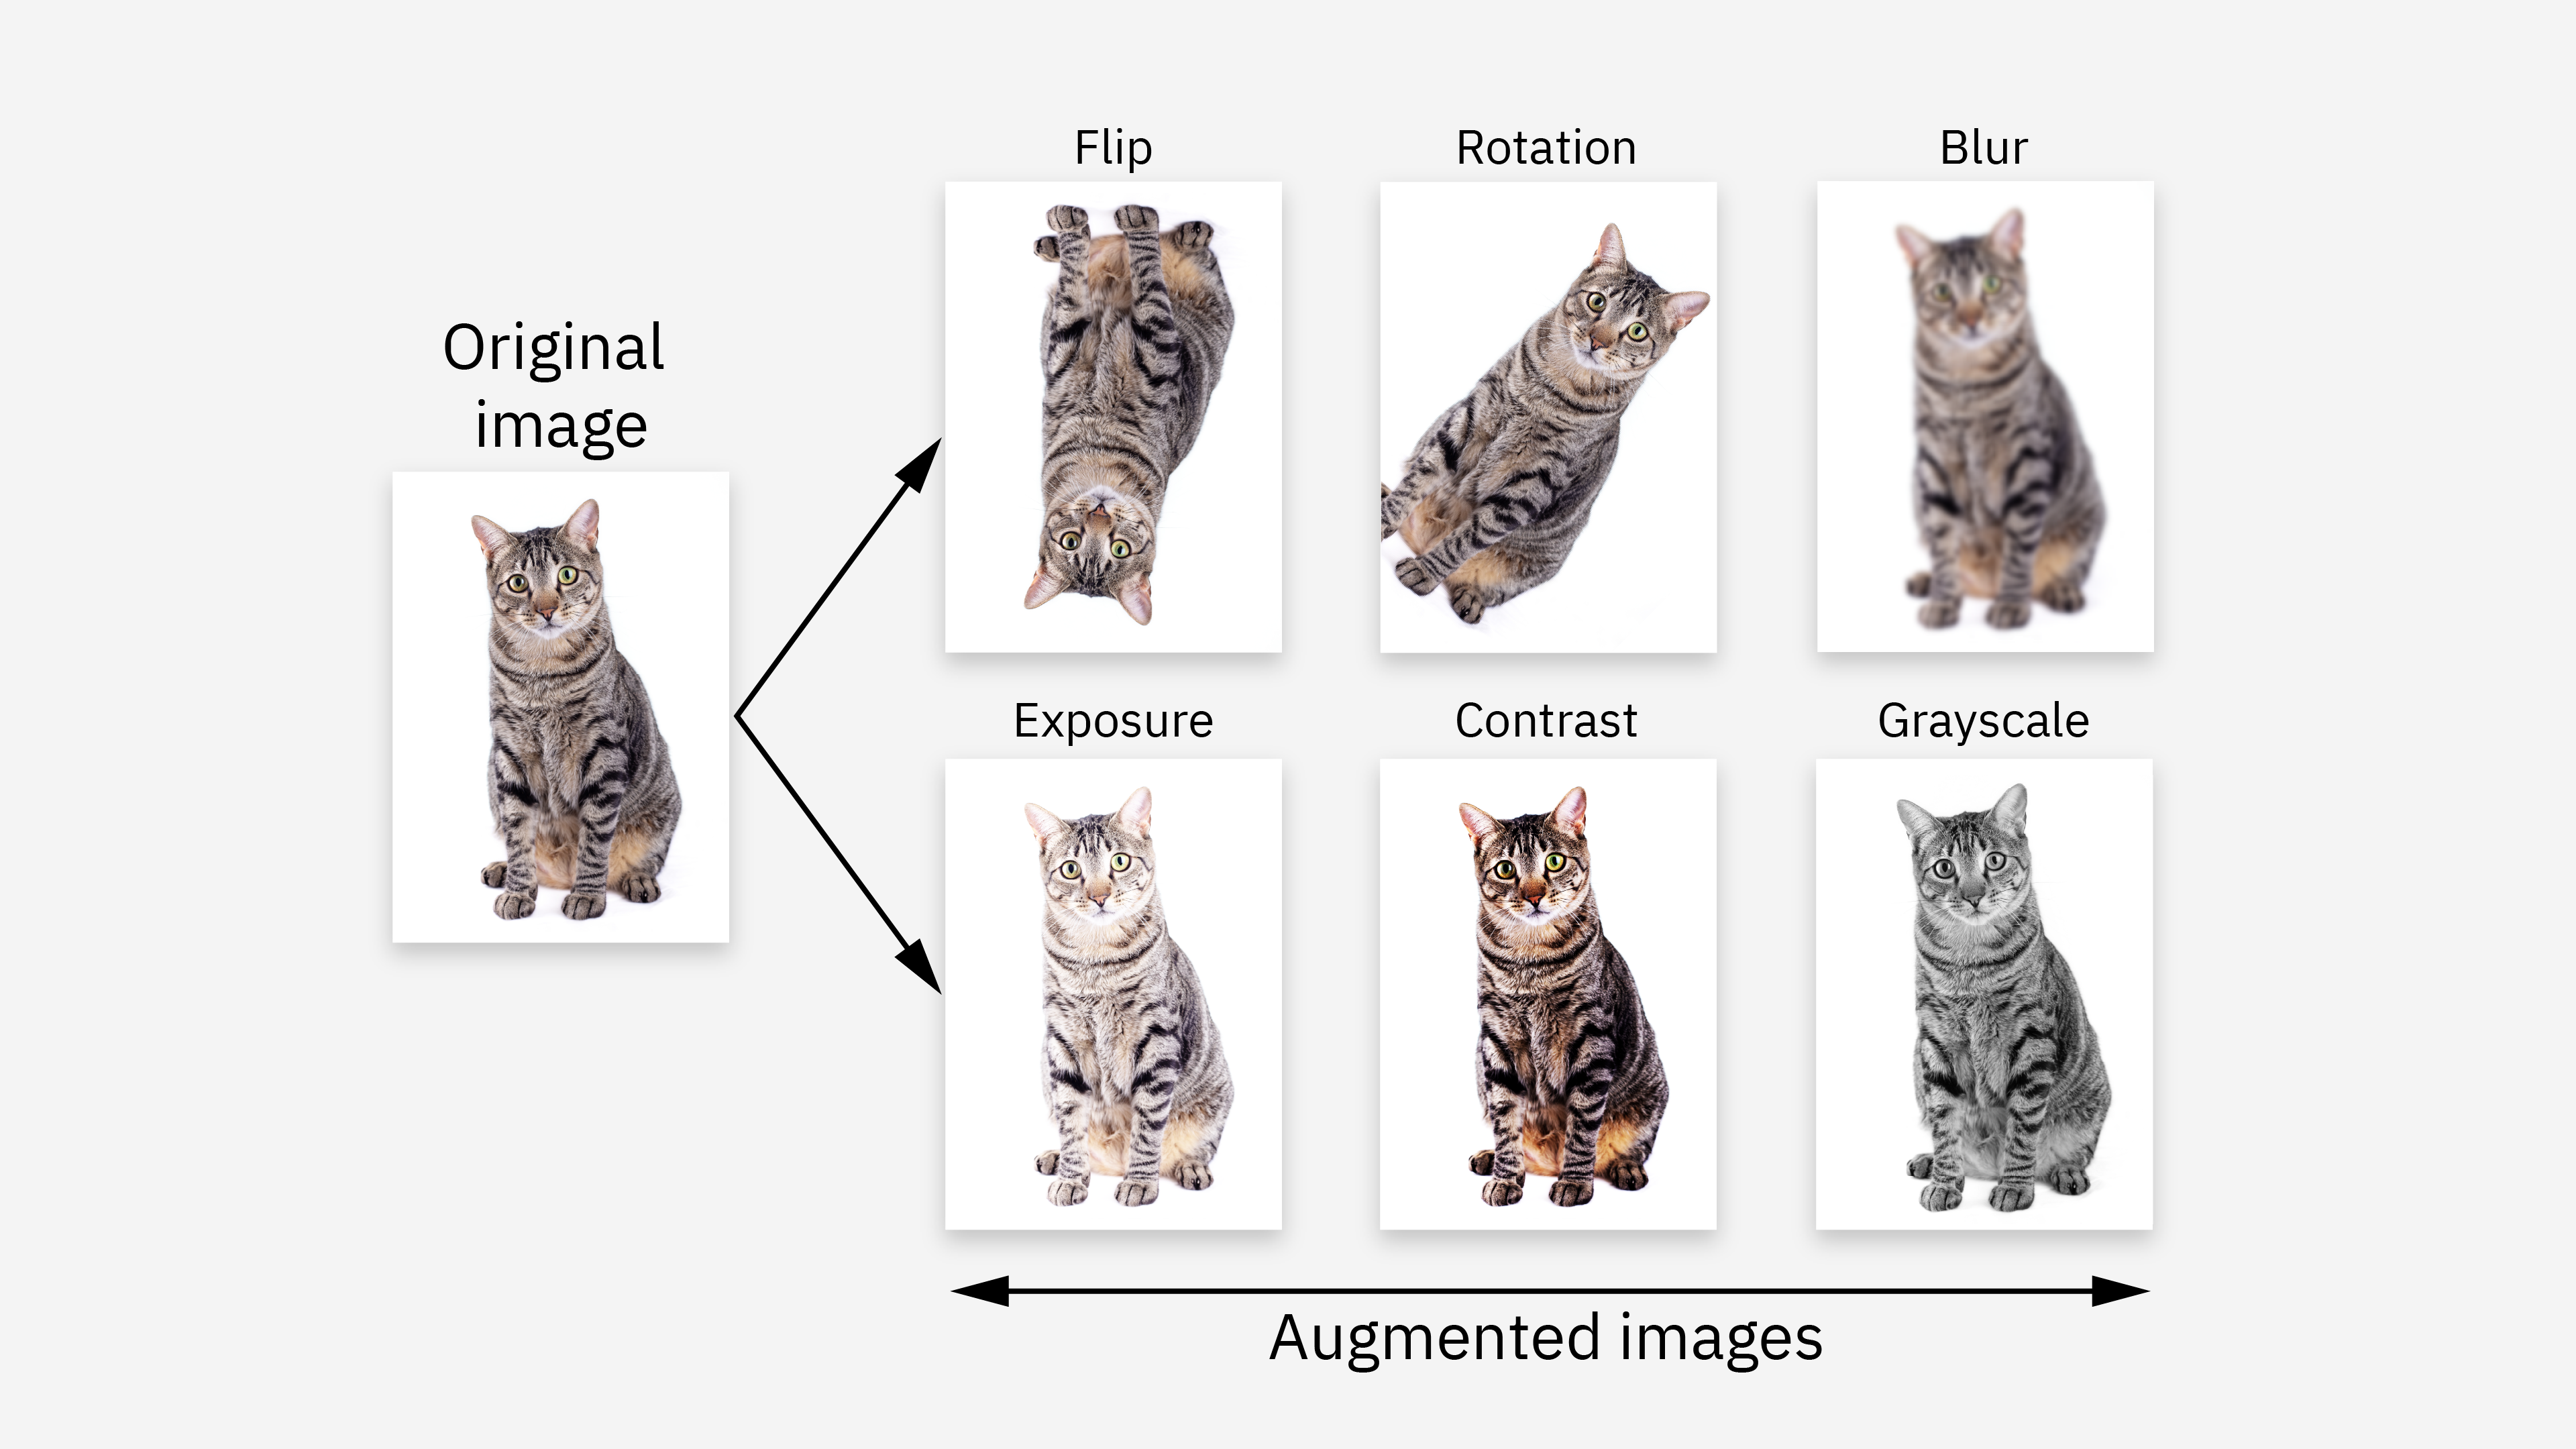

¿cGAN o aumento clásico? Datos sintéticos con pocos datos reales?
Si solo tengo 50 imágenes etiquetadas por clase, ¿vale la pena entrenar una GAN condicional para generar más datos, o basta con el aumento de datos clásico (volteos, rotaciones, traslaciones)?

Con las 60 000 imágenes de FashionMNIST cualquier CNN supera el 90 % y no se nota ninguna diferencia. Con 500 imágenes (50 por clase) el problema se vuelve real y medible.

Las tres reglas de un experimento honesto
Sin fuga: la cGAN solo ve las mismas 500 imágenes que el clasificador.
Mismo presupuesto: todos los clasificadores tienen la misma arquitectura y el mismo número de pasos de entrenamiento (no de épocas: con más imágenes habría más pasos y la comparación sería injusta).
Evaluación en reales y con varias semillas: siempre en las 10 000 imágenes reales de prueba, con 3 semillas, reportando media ± desviación.

## Librerías

In [2]:
import os, time, math, copy, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from torchvision import datasets
from torchvision.utils import make_grid
from scipy import linalg
from IPython.display import display
warnings.filterwarnings("ignore")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| dispositivo:", DEVICE,
      "(" + torch.cuda.get_device_name(0) + ")" if DEVICE.type == "cuda" else "← activa la GPU: Entorno de ejecución → Cambiar tipo de entorno → T4")

def fijar_semilla(s=0):
    torch.manual_seed(s); np.random.seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

def mostrar_grid(x, titulo="", nrow=10, tam=(8, 8)):
    """x en [-1, 1], forma (N, C, H, W)."""
    g = make_grid(x.detach().cpu()[: nrow * nrow], nrow=nrow, normalize=True, value_range=(-1, 1), pad_value=1)
    plt.figure(figsize=tam); plt.imshow(g.permute(1, 2, 0).numpy(), cmap="gray"); plt.axis("off"); plt.title(titulo); plt.show()

PyTorch 2.14.1+cu130 | dispositivo: cuda (Tesla T4)


In [4]:
NOMBRES_CLASES = {
    "FashionMNIST": ["camiseta", "pantalón", "suéter", "vestido", "abrigo", "sandalia", "camisa", "tenis", "bolsa", "botín"],
    "MNIST": [str(i) for i in range(10)],
    "CIFAR10": ["avión", "auto", "pájaro", "gato", "venado", "perro", "rana", "caballo", "barco", "camión"],
}

def cargar_tensor(nombre="FashionMNIST", split="train"):
    """Descarga el dataset y lo deja COMPLETO en memoria como tensor (N, C, 32, 32) en [-1, 1].
    Tenerlo en la GPU evita el DataLoader y acelera muchísimo el entrenamiento de GANs pequeñas."""
    clase = getattr(datasets, nombre)
    ds = clase("datos", train=(split == "train"), download=True)
    x = torch.as_tensor(np.asarray(ds.data))
    y = torch.as_tensor(np.asarray(ds.targets)).long()
    if x.ndim == 3:                          # escala de grises 28x28 → (N, 1, 32, 32) con relleno de 2 px
        x = F.pad(x.unsqueeze(1), (2, 2, 2, 2))
    else:                                    # CIFAR10 viene como (N, 32, 32, 3)
        x = x.permute(0, 3, 1, 2)
    x = x.float().div(255).mul(2).sub(1)    # [0, 255] → [-1, 1] (coincide con la tanh del generador)
    return x.to(DEVICE), y.to(DEVICE)

def lotes(x, y, batch, mezclar=True):
    idx = torch.randperm(len(x), device=x.device) if mezclar else torch.arange(len(x), device=x.device)
    for i in range(0, len(x) - batch + 1, batch):   # se descarta el último lote incompleto (BN lo agradece)
        j = idx[i:i + batch]
        yield x[j], y[j]

In [5]:
def _bn(n, usar):            # BatchNorm o "nada", para poder hacer ablaciones
    return nn.BatchNorm2d(n) if usar else nn.Identity()

class Generador(nn.Module):
    """DCGAN para 32x32: z (nz) → 4x4 → 8x8 → 16x16 → 32x32. Sin capas densas, solo convoluciones transpuestas."""
    def __init__(self, nz=100, ngf=64, canales=1, bn=True):
        super().__init__()
        b = not bn            # si hay BN el sesgo es redundante
        self.red = nn.Sequential(
            nn.ConvTranspose2d(nz, ngf * 4, 4, 1, 0, bias=b), _bn(ngf * 4, bn), nn.ReLU(True),       # 4x4
            nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=b), _bn(ngf * 2, bn), nn.ReLU(True),  # 8x8
            nn.ConvTranspose2d(ngf * 2, ngf, 4, 2, 1, bias=b), _bn(ngf, bn), nn.ReLU(True),          # 16x16
            nn.ConvTranspose2d(ngf, canales, 4, 2, 1, bias=True), nn.Tanh(),                        # 32x32 en [-1, 1]
        )
    def forward(self, z):
        return self.red(z.view(z.size(0), -1, 1, 1))

class Discriminador(nn.Module):
    """Espejo del generador: convoluciones con stride 2 en lugar de pooling, LeakyReLU, y un LOGIT final.
    No ponemos Sigmoid: usamos BCEWithLogitsLoss, que es numéricamente estable."""
    def __init__(self, ndf=64, canales=1, bn=True):
        super().__init__()
        b = not bn
        self.red = nn.Sequential(
            nn.Conv2d(canales, ndf, 4, 2, 1, bias=True), nn.LeakyReLU(0.2, True),                  # 16x16 (sin BN en la 1a capa)
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=b), _bn(ndf * 2, bn), nn.LeakyReLU(0.2, True),    # 8x8
            nn.Conv2d(ndf * 2, ndf * 4, 4, 2, 1, bias=b), _bn(ndf * 4, bn), nn.LeakyReLU(0.2, True),# 4x4
            nn.Conv2d(ndf * 4, 1, 4, 1, 0, bias=True),                                             # 1x1 → logit
        )
    def forward(self, x):
        return self.red(x).view(-1)

def init_dcgan(m):
    """Inicialización del artículo DCGAN (Radford et al., 2016): pesos ~ N(0, 0.02); BN: γ ~ N(1, 0.02), β = 0."""
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d, nn.Linear)):
        nn.init.normal_(m.weight, 0.0, 0.02)
        if m.bias is not None: nn.init.zeros_(m.bias)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)

def contar_parametros(m):
    return sum(p.numel() for p in m.parameters())

In [6]:
class GeneradorCond(nn.Module):
    """cGAN (Mirza y Osindero, 2014) con arquitectura DCGAN.
    La etiqueta y entra como un embedding aprendido que se CONCATENA al ruido z."""
    def __init__(self, nz=100, n_clases=10, dim_emb=50, ngf=64, canales=1):
        super().__init__()
        self.emb = nn.Embedding(n_clases, dim_emb)
        self.g = Generador(nz + dim_emb, ngf, canales, bn=True)
    def forward(self, z, y):
        return self.g(torch.cat([z, self.emb(y)], dim=1))

class DiscriminadorCond(nn.Module):
    """La etiqueta se convierte en un 'mapa' de 32x32 y se añade como canal extra a la imagen:
    D '¿es una imagen real DE ESTA CLASE?'."""
    def __init__(self, n_clases=10, ndf=64, canales=1, lado=32):
        super().__init__()
        self.lado = lado
        self.emb = nn.Embedding(n_clases, lado * lado)
        self.d = Discriminador(ndf, canales + 1, bn=True)
    def forward(self, x, y):
        mapa = self.emb(y).view(-1, 1, self.lado, self.lado)
        return self.d(torch.cat([x, mapa], dim=1))

In [7]:
class Juez(nn.Module):
    """CNN pequeña entrenada con datos REALES. Nos sirve de 'evaluador externo' de las imágenes generadas:
    (1) qué clase cree que es cada muestra → cobertura de modos; (2) sus características de 128-d → FID de dominio."""
    def __init__(self, canales=1, n_clases=10):
        super().__init__()
        self.cuerpo = nn.Sequential(
            nn.Conv2d(canales, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),   # 16
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),        # 8
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
            nn.Flatten())
        self.cabeza = nn.Linear(128, n_clases)
    def forward(self, x): return self.cabeza(self.cuerpo(x))
    @torch.no_grad()
    def caracteristicas(self, x, lote=500):
        self.eval(); return torch.cat([self.cuerpo(x[i:i + lote]) for i in range(0, len(x), lote)])
    @torch.no_grad()
    def probabilidades(self, x, lote=500):
        self.eval(); return torch.cat([F.softmax(self(x[i:i + lote]), 1) for i in range(0, len(x), lote)])

def entrenar_juez(x, y, x_te, y_te, epocas=3, batch=256, aumento=False, semilla=0, verbose=True):
    fijar_semilla(semilla)
    m = Juez(x.shape[1], int(y.max()) + 1).to(DEVICE)
    opt = torch.optim.Adam(m.parameters(), 1e-3)
    for ep in range(epocas):
        m.train()
        for xb, yb in lotes(x, y, min(batch, len(x))):
            if aumento:   # aumento "clásico": desplazamientos aleatorios de ±2 px y espejo horizontal
                xb = torch.roll(xb, shifts=(int(np.random.randint(-2, 3)), int(np.random.randint(-2, 3))), dims=(2, 3))
                if np.random.rand() < 0.5: xb = xb.flip(3)
            loss = F.cross_entropy(m(xb), yb)
            opt.zero_grad(); loss.backward(); opt.step()
    acc = (m.probabilidades(x_te).argmax(1) == y_te).float().mean().item()
    if verbose: print(f"Juez: exactitud en prueba real = {acc:.3f}")
    return m, acc

In [8]:
def estadisticos(feats):
    f = feats.double().cpu().numpy()
    return f.mean(0), np.cov(f, rowvar=False)

def distancia_frechet(mu1, s1, mu2, s2):
    """FID = ||μ1 − μ2||² + Tr(Σ1 + Σ2 − 2 (Σ1 Σ2)^{1/2})   (Heusel et al., 2017)"""
    diff = mu1 - mu2
    covmean = linalg.sqrtm(s1 @ s2)
    if not np.isfinite(covmean).all():          # estabilización numérica recomendada en la implementación oficial
        eps = np.eye(len(s1)) * 1e-6
        covmean = linalg.sqrtm((s1 + eps) @ (s2 + eps))
    covmean = np.real(covmean)
    return float(diff @ diff + np.trace(s1) + np.trace(s2) - 2 * np.trace(covmean))

def fid_dominio(juez, x_a, x_b):
    """FID calculado con las características del JUEZ (128-d)"""
    return distancia_frechet(*estadisticos(juez.caracteristicas(x_a)), *estadisticos(juez.caracteristicas(x_b)))

In [9]:
DATASET = "FashionMNIST"
X_tr, Y_tr = cargar_tensor(DATASET, "train"); X_te, Y_te = cargar_tensor(DATASET, "test")
CLASES = NOMBRES_CLASES[DATASET]; CANALES = X_tr.shape[1]; N_CLASES = len(CLASES)

RUTA_JUEZ = f"juez_{DATASET}.pt"     # sube el del jueves 29 con: from google.colab import files; files.upload()
if os.path.exists(RUTA_JUEZ):
    juez = Juez(CANALES).to(DEVICE); juez.load_state_dict(torch.load(RUTA_JUEZ, map_location=DEVICE)); juez.eval()
    print("Juez cargado · exactitud en prueba:", round((juez.probabilidades(X_te).argmax(1) == Y_te).float().mean().item(), 3))
else:
    juez, _ = entrenar_juez(X_tr, Y_tr, X_te, Y_te, epocas=3); torch.save(juez.state_dict(), RUTA_JUEZ)

100%|██████████| 26.4M/26.4M [00:00<00:00, 118MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 4.48MB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 67.9MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 12.6MB/s]


Juez: exactitud en prueba real = 0.776


## Parte

DCGAN (pérdida no saturante, BCE con logits, *label smoothing*, inicialización N(0, 0.02), Adam 2·10⁻⁴ y β₁ = 0.5). Cambia lo que entra a cada red:

* **G(z, y)**: el *embedding* de la etiqueta se concatena al ruido.
* **D(x, y)**: la etiqueta entra como canal extra. Para los lotes falsos usamos **etiquetas aleatorias** uniformes, de modo que G practica todas las clases por igual.

Añadimos dos opciones útiles cuando hay **pocos datos**: ruido de instancia y un **aumento diferenciable** (desplazamiento y espejo aplicados **por igual** a reales y falsas antes de D, en el espíritu de *DiffAugment*, Zhao et al., 2020) para que D no memorice el conjunto pequeño.

El entrenamiento se mide en **iteraciones** (no épocas) para poder comparar un dataset de 60 000 imágenes con uno de 500.

In [10]:
def aumento_diferenciable(x, activo):
    if not activo: return x
    dx, dy = np.random.randint(-3, 4, size=2)
    x = torch.roll(x, shifts=(int(dx), int(dy)), dims=(2, 3))
    return x.flip(3) if np.random.rand() < 0.5 else x

@torch.no_grad()
def muestras_cond(G, n_por_clase=100, nz=100, semilla=0):
    g = torch.Generator(device=DEVICE).manual_seed(semilla)
    y = torch.arange(N_CLASES, device=DEVICE).repeat_interleave(n_por_clase)
    z = torch.randn(len(y), nz, device=DEVICE, generator=g)
    G.eval(); x = torch.cat([G(z[i:i + 500], y[i:i + 500]) for i in range(0, len(y), 500)]); G.train()
    return x, y

@torch.no_grad()
def evaluar_cgan(G, nz=100, n_por_clase=200):
    x, y = muestras_cond(G, n_por_clase, nz, semilla=123)
    pred = juez.probabilidades(x).argmax(1)
    return dict(acc_condicional=round((pred == y).float().mean().item(), 3),
                fid_dominio=round(fid_dominio(juez, X_te[:len(x)], x), 2))

def entrenar_cgan(x, y, iteraciones=4000, batch=128, nz=100, suavizado=0.9, ruido_instancia=0.0,
                  aumento_D=False, semilla=0, cada=500, nombre="cgan"):
    fijar_semilla(semilla)
    G = GeneradorCond(nz, N_CLASES, 50, 64, CANALES).to(DEVICE)
    D = DiscriminadorCond(N_CLASES, 64, CANALES).to(DEVICE)
    G.apply(init_dcgan); D.apply(init_dcgan)
    oG = torch.optim.Adam(G.parameters(), 2e-4, betas=(0.5, 0.999))
    oD = torch.optim.Adam(D.parameters(), 2e-4, betas=(0.5, 0.999))
    bce = nn.BCEWithLogitsLoss()
    batch = min(batch, len(x)); flujo = iter(()); hist, t0 = [], time.time()
    for it in range(1, iteraciones + 1):
        try: xr, yr = next(flujo)
        except StopIteration:
            flujo = lotes(x, y, batch); xr, yr = next(flujo)
        b = len(xr); sigma = ruido_instancia * (1 - it / iteraciones)
        rd = (lambda t: aumento_diferenciable(t + sigma * torch.randn_like(t), aumento_D)) if sigma > 0 else (lambda t: aumento_diferenciable(t, aumento_D))
        # (1) D: real de su clase → suavizado ; falsa con etiqueta aleatoria → 0
        yf = torch.randint(0, N_CLASES, (b,), device=DEVICE)
        with torch.no_grad(): xf = G(torch.randn(b, nz, device=DEVICE), yf)
        o_r, o_f = D(rd(xr), yr), D(rd(xf), yf)
        lD = bce(o_r, torch.full_like(o_r, suavizado)) + bce(o_f, torch.zeros_like(o_f))
        oD.zero_grad(); lD.backward(); oD.step()
        # (2) G: no saturante
        yg = torch.randint(0, N_CLASES, (b,), device=DEVICE)
        o_g = D(rd(G(torch.randn(b, nz, device=DEVICE), yg)), yg)
        lG = bce(o_g, torch.ones_like(o_g))
        oG.zero_grad(); lG.backward(); oG.step()
        if it % cada == 0 or it == iteraciones:
            ev = evaluar_cgan(G, nz)
            hist.append(dict(iteracion=it, loss_D=lD.item(), loss_G=lG.item(), D_x=torch.sigmoid(o_r).mean().item(),
                             D_Gz=torch.sigmoid(o_f).mean().item(), **ev))
            print(f"[{nombre}] it {it:>5}/{iteraciones}  loss_D {lD.item():.3f}  loss_G {lG.item():.3f}  "
                  f"acc_cond {ev['acc_condicional']:.3f}  FID-d {ev['fid_dominio']:.1f}  ({time.time() - t0:.0f} s)")
    return G, pd.DataFrame(hist)

ITER_COMPLETO = 4000      # ≈ 8.5 épocas de FashionMNIST con lotes de 128
G_completo, h_completo = entrenar_cgan(X_tr, Y_tr, ITER_COMPLETO, nombre="cGAN-60k")

[cGAN-60k] it   500/4000  loss_D 0.890  loss_G 2.007  acc_cond 0.528  FID-d 8.7  (26 s)
[cGAN-60k] it  1000/4000  loss_D 0.902  loss_G 2.234  acc_cond 0.654  FID-d 5.5  (54 s)
[cGAN-60k] it  1500/4000  loss_D 0.888  loss_G 1.809  acc_cond 0.678  FID-d 4.2  (82 s)
[cGAN-60k] it  2000/4000  loss_D 1.168  loss_G 1.410  acc_cond 0.569  FID-d 2.9  (112 s)
[cGAN-60k] it  2500/4000  loss_D 1.021  loss_G 1.454  acc_cond 0.649  FID-d 2.0  (141 s)
[cGAN-60k] it  3000/4000  loss_D 1.251  loss_G 1.294  acc_cond 0.742  FID-d 1.7  (170 s)
[cGAN-60k] it  3500/4000  loss_D 1.078  loss_G 1.366  acc_cond 0.708  FID-d 1.2  (199 s)
[cGAN-60k] it  4000/4000  loss_D 1.177  loss_G 1.960  acc_cond 0.737  FID-d 1.0  (228 s)


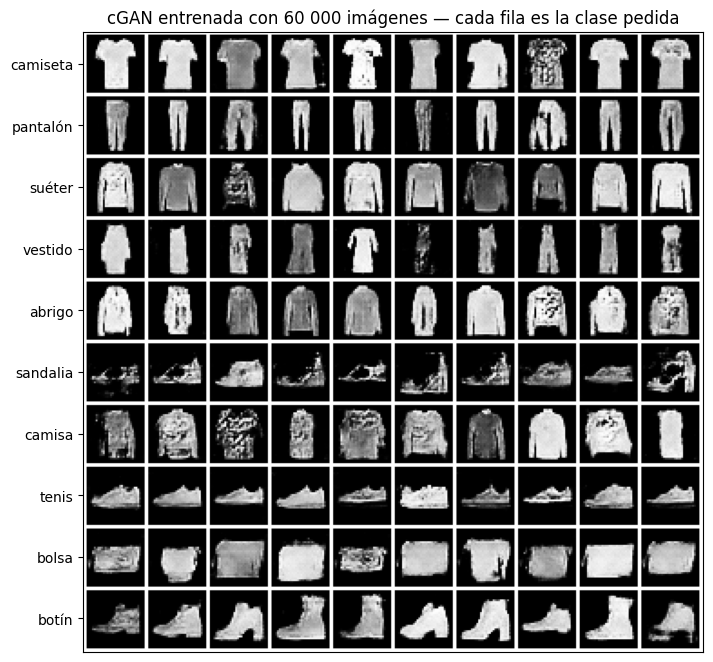

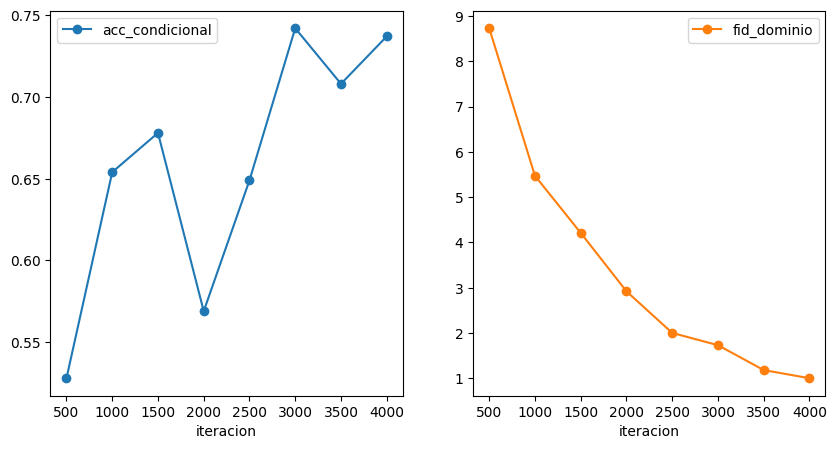

In [11]:
def rejilla_por_clase(G, titulo, nz=100):
    x, _ = muestras_cond(G, n_por_clase=10, nz=nz, semilla=7)
    g = make_grid(x.cpu(), nrow=10, normalize=True, value_range=(-1, 1), pad_value=1)
    plt.figure(figsize=(8, 8.4)); plt.imshow(g.permute(1, 2, 0)); plt.title(titulo)
    plt.yticks([17 + 34 * i for i in range(N_CLASES)], CLASES); plt.xticks([]); plt.show()

rejilla_por_clase(G_completo, "cGAN entrenada con 60 000 imágenes — cada fila es la clase pedida")
h_completo.plot(x="iteracion", y=["acc_condicional", "fid_dominio"], subplots=True, marker="o", figsize=(10, 5), layout=(1, 2)); plt.show()

Inspección visual ¿todas las filas corresponden a la clase pedida?

No, en todas las filas hay formas de prendas diferentes

¿Hay diversidad de cada fila (colores, formas, poses) o se repite la misma prenda?

Si hay diversidad en las formas e intencidad de color en las prendas de cada fila

## Parte B

Dos preguntas distintas, dos métricas:
* **¿Genera lo que se le pide?** → *exactitud condicional*: el juez clasifica las muestras de la clase *c* y medimos cuántas reconoce como *c*.
* **¿Se parece a la distribución real de esa clase?** → **FID de dominio por clase**: 1000 generadas de la clase *c* vs. las 1000 reales de prueba de esa clase.

,clase,acc_condicional,fid_dominio
0,camiseta,0.325,1.102
1,pantalón,0.973,0.944
2,suéter,0.113,1.185
3,vestido,0.849,1.263
4,abrigo,0.984,0.538
5,sandalia,0.993,3.412
6,camisa,0.500,1.670
7,tenis,0.881,0.825
8,bolsa,0.802,4.716
9,botín,0.897,1.462


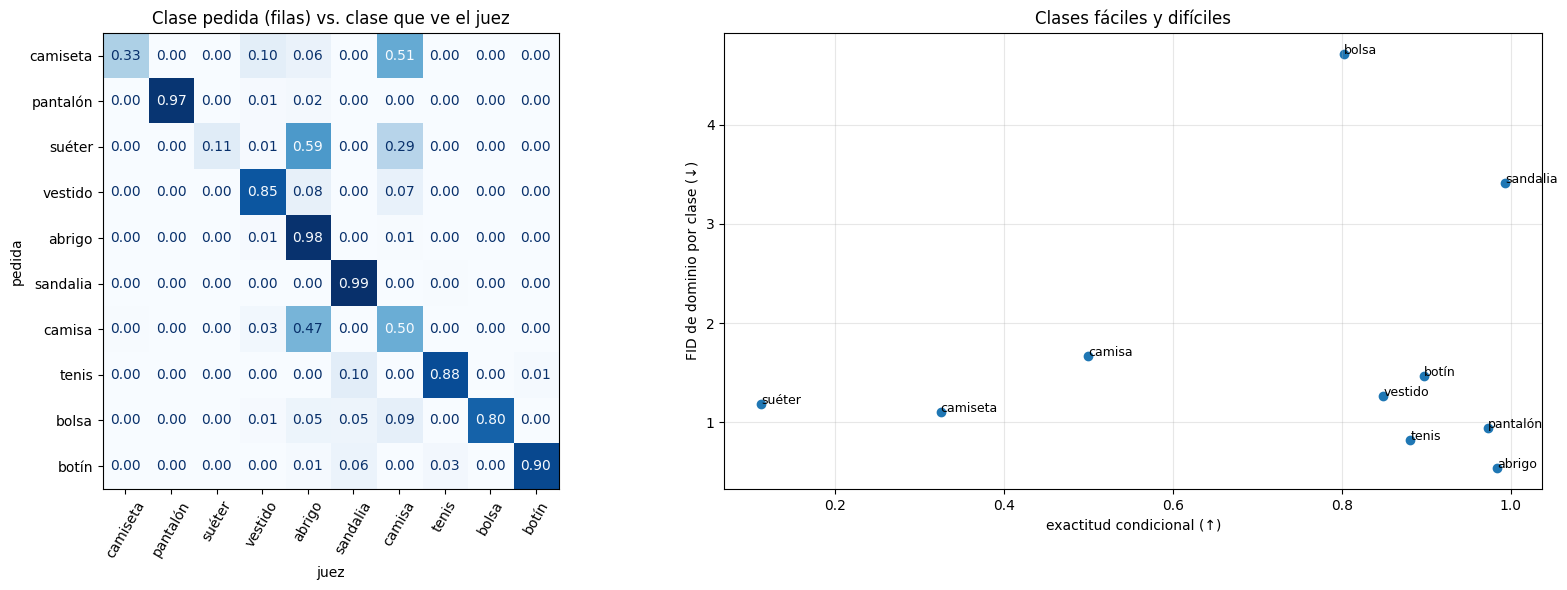

In [12]:
@torch.no_grad()
def evaluacion_por_clase(G, nz=100, n=1000):
    x, y = muestras_cond(G, n, nz, semilla=99)
    pred = juez.probabilidades(x).argmax(1)
    filas = []
    for c in range(N_CLASES):
        xc = x[y == c]; xr = X_te[Y_te == c][:n]
        filas.append(dict(clase=CLASES[c], acc_condicional=(pred[y == c] == c).float().mean().item(),
                          fid_dominio=fid_dominio(juez, xr, xc)))
    return pd.DataFrame(filas), y.cpu(), pred.cpu()

tabla_clase, y_ped, y_pred = evaluacion_por_clase(G_completo)
display(tabla_clase.round(3))

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
fig, ax = plt.subplots(1, 2, figsize=(17, 6))
ConfusionMatrixDisplay(confusion_matrix(y_ped, y_pred, normalize="true"), display_labels=CLASES).plot(
    ax=ax[0], cmap="Blues", values_format=".2f", colorbar=False)
ax[0].set(title="Clase pedida (filas) vs. clase que ve el juez", xlabel="juez", ylabel="pedida"); ax[0].tick_params(axis="x", rotation=60)
ax[1].scatter(tabla_clase.acc_condicional, tabla_clase.fid_dominio)
for _, f in tabla_clase.iterrows(): ax[1].annotate(f.clase, (f.acc_condicional, f.fid_dominio), fontsize=9)
ax[1].set(xlabel="exactitud condicional (↑)", ylabel="FID de dominio por clase (↓)", title="Clases fáciles y difíciles"); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig("cgan_evaluacion_por_clase.png", dpi=110); plt.show()

¿Qué clases confunde más la cGAN?

camiseta - camisa

sueter - abrigo

camisa - abrigo

Tambien pueden ser:

sueter - camisa

camiseta - abrigo

¿Coinciden con las que confunde un clasificador normal (p. ej., camisa/camiseta/suéter/abrigo)?

Si porque la forma es muy parecida

¿Es un problema del generador, del juez, o de los datos?

Del juez porque clasifica incorrectamente las imágenes reales y falsas, o no identifica si corresponden a la etiqueta indicada.


## Parte C

¿Ayudan los datos sintéticos cuando hay pocos reales?

Si ayudan pero solo para hacer el complemento de los datos faltantes, y ahi que evaluar cuando si nos necesarios porque aveces dan mejores resultados si solo utilizamos los datos que tenemos



**Escenario.** Solo tenemos `N_POR_CLASE` imágenes reales etiquetadas por clase. Comparamos:

| Clave | Datos de entrenamiento del clasificador | Protocolo |
|---|---|---|
| `R` | Solo las imágenes reales limitadas | TRTR (referencia) |
| `R+aum` | Reales limitadas + aumento clásico (desplazamiento ±2 px, espejo) | TRTR con aumento |
| `S_honesta` | Solo sintéticas de una cGAN entrenada **con las mismas imágenes limitadas** | TSTR |
| `R+S_honesta` | Reales limitadas + sintéticas honestas | TRSTR |
| `R+S_fuga` ⚠️ | Reales limitadas + sintéticas de la cGAN de la Parte A (vio **60 000** imágenes) | **No válido como resultado:** cota con fuga de información |
| `R_60k` | Las 60 000 reales | Techo de referencia |

Datos limitados: 200 imágenes reales (20 por clase)


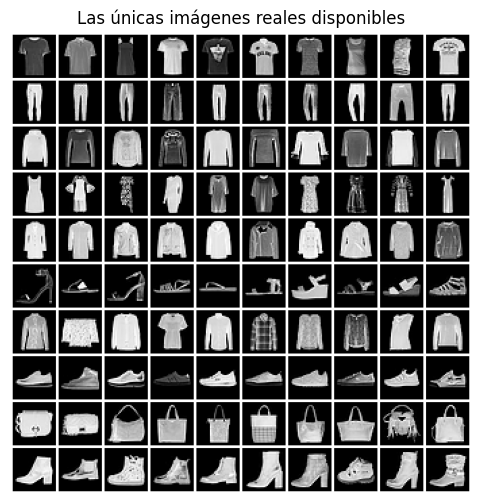

In [13]:
N_POR_CLASE = 20        # probar 20, 50 o 200
SINT_POR_CLASE = 500      # imágenes sintéticas por clase
PASOS_CLF = 800           # mismo presupuesto de entrenamiento para todos los clasificadores
SEMILLAS = [0, 1, 2]

def subconjunto_limitado(n, semilla=0):
    g = torch.Generator(device="cpu").manual_seed(semilla)
    idx = torch.cat([torch.nonzero(Y_tr.cpu() == c).view(-1)[torch.randperm(int((Y_tr == c).sum()), generator=g)[:n]]
                     for c in range(N_CLASES)])
    return X_tr[idx.to(DEVICE)], Y_tr[idx.to(DEVICE)]

def entrenar_clasificador(x, y, pasos=PASOS_CLF, batch=64, aumento=False, semilla=0):
    """Mismo clasificador para todas las condiciones; número de PASOS fijo (no de épocas)."""
    fijar_semilla(semilla)
    m = Juez(CANALES, N_CLASES).to(DEVICE); opt = torch.optim.Adam(m.parameters(), 1e-3)
    flujo = iter(()); batch = min(batch, len(x))
    for _ in range(pasos):
        try: xb, yb = next(flujo)
        except StopIteration:
            flujo = lotes(x, y, batch); xb, yb = next(flujo)
        if aumento:
            xb = torch.roll(xb, shifts=(int(np.random.randint(-2, 3)), int(np.random.randint(-2, 3))), dims=(2, 3))
            if np.random.rand() < 0.5: xb = xb.flip(3)
        m.train(); loss = F.cross_entropy(m(xb), yb)
        opt.zero_grad(); loss.backward(); opt.step()
    pred = m.probabilidades(X_te).argmax(1)
    return (pred == Y_te).float().mean().item(), pred

X_lim, Y_lim = subconjunto_limitado(N_POR_CLASE)
print(f"Datos limitados: {len(X_lim)} imágenes reales ({N_POR_CLASE} por clase)")
mostrar_grid(X_lim[torch.argsort(Y_lim)][:: max(1, N_POR_CLASE // 10)][:100], "Las únicas imágenes reales disponibles", tam=(6, 6))

### C.1 La cGAN2
Con tan pocos datos D puede **memorizar** el conjunto real y dejar de dar señal útil. Por eso activamos el aumento diferenciable y el ruido de instancia.

[cGAN-200] it   500/3000  loss_D 1.404  loss_G 0.686  acc_cond 0.363  FID-d 10.9  (12 s)
[cGAN-200] it  1000/3000  loss_D 1.139  loss_G 1.048  acc_cond 0.242  FID-d 11.2  (25 s)
[cGAN-200] it  1500/3000  loss_D 0.962  loss_G 1.125  acc_cond 0.579  FID-d 7.7  (38 s)
[cGAN-200] it  2000/3000  loss_D 1.402  loss_G 1.531  acc_cond 0.637  FID-d 5.2  (50 s)
[cGAN-200] it  2500/3000  loss_D 1.707  loss_G 0.725  acc_cond 0.467  FID-d 8.0  (62 s)
[cGAN-200] it  3000/3000  loss_D 1.389  loss_G 1.273  acc_cond 0.560  FID-d 4.7  (75 s)


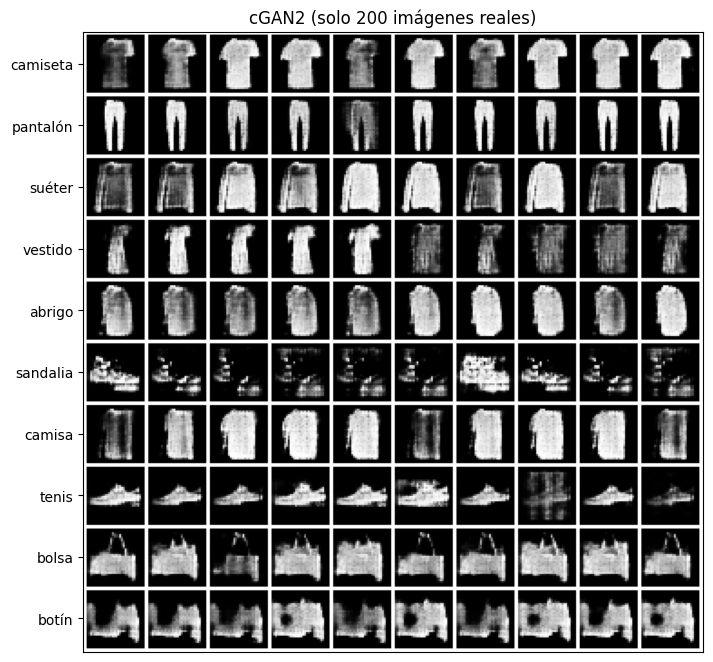

In [14]:
ITER_LIMITADO = 3000
G_honesta, h_honesta = entrenar_cgan(X_lim, Y_lim, ITER_LIMITADO, batch=64, ruido_instancia=0.1, aumento_D=True,
                                     nombre=f"cGAN-{len(X_lim)}")
rejilla_por_clase(G_honesta, f"cGAN2 (solo {len(X_lim)} imágenes reales)")

Entrena otra cGAN2 **sin** `aumento_D` ni ruido (`ruido_instancia=0.0, aumento_D=False`). Compara rejilla, exactitud condicional y FID. ¿Qué le pasa a D con 500 imágenes sin aumento?

El discriminador se sobreajusta poquito y domina rapidamente al generador. Ya que el discriminado al tener poquitos datos los memoriza todos.

[cGAN-200] it   500/3000  loss_D 0.638  loss_G 2.753  acc_cond 0.480  FID-d 9.6  (12 s)
[cGAN-200] it  1000/3000  loss_D 0.555  loss_G 2.273  acc_cond 0.591  FID-d 11.7  (24 s)
[cGAN-200] it  1500/3000  loss_D 0.530  loss_G 3.824  acc_cond 0.704  FID-d 8.7  (37 s)
[cGAN-200] it  2000/3000  loss_D 0.462  loss_G 3.405  acc_cond 0.679  FID-d 9.4  (50 s)
[cGAN-200] it  2500/3000  loss_D 0.441  loss_G 4.858  acc_cond 0.697  FID-d 8.9  (62 s)
[cGAN-200] it  3000/3000  loss_D 0.391  loss_G 4.110  acc_cond 0.723  FID-d 8.0  (75 s)


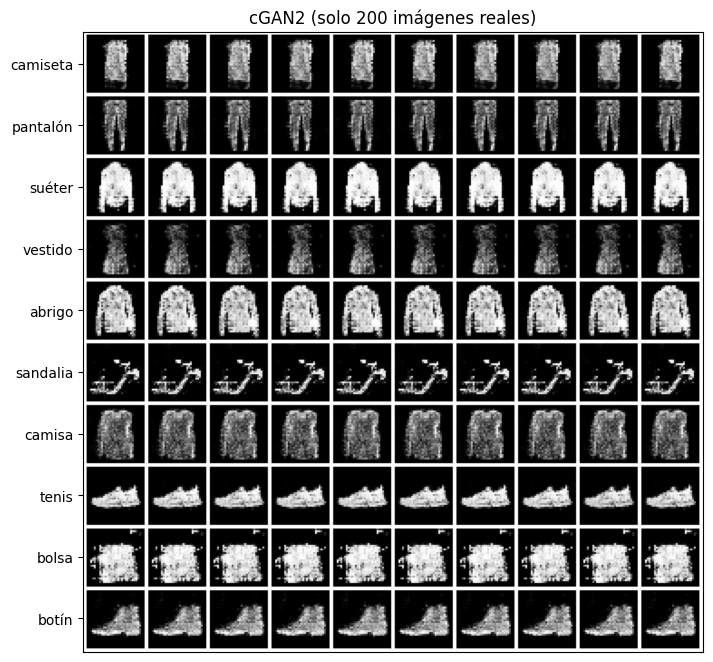

In [15]:
ITER_LIMITADO = 3000
G_honesta, h_honesta = entrenar_cgan(X_lim, Y_lim, ITER_LIMITADO, batch=64, ruido_instancia=0.0, aumento_D=False,
                                     nombre=f"cGAN-{len(X_lim)}")
rejilla_por_clase(G_honesta, f"cGAN2 (solo {len(X_lim)} imágenes reales)")

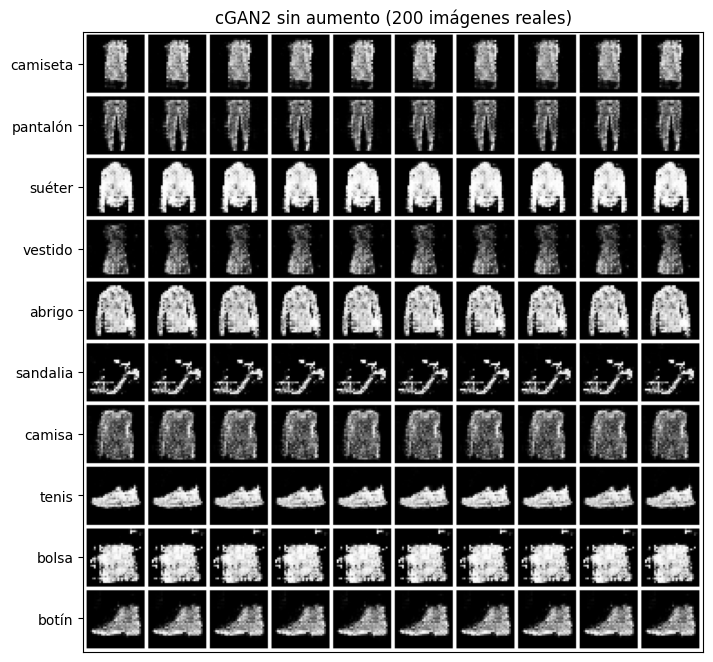

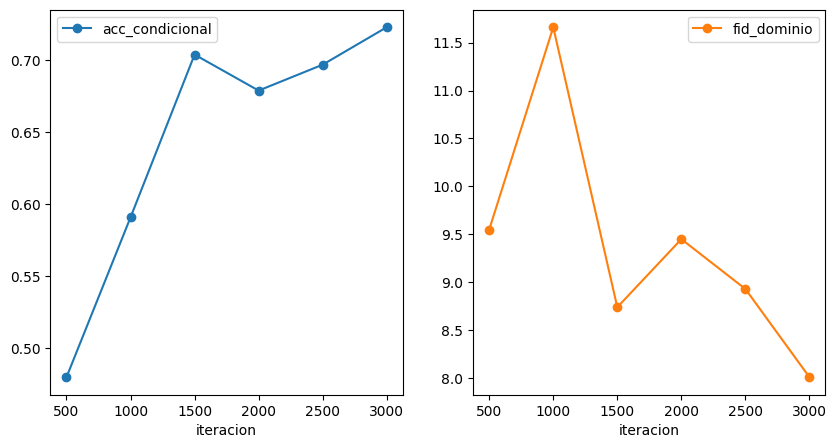

In [16]:
def rejilla_por_clase(G, titulo, nz=100):
    x, _ = muestras_cond(G, n_por_clase=10, nz=nz, semilla=7)
    g = make_grid(x.cpu(), nrow=10, normalize=True, value_range=(-1, 1), pad_value=1)
    plt.figure(figsize=(8, 8.4)); plt.imshow(g.permute(1, 2, 0)); plt.title(titulo)
    plt.yticks([17 + 34 * i for i in range(N_CLASES)], CLASES); plt.xticks([]); plt.show()

rejilla_por_clase(G_honesta, f"cGAN2 sin aumento ({len(X_lim)} imágenes reales)")
h_honesta.plot(x="iteracion", y=["acc_condicional", "fid_dominio"], subplots=True, marker="o", figsize=(10, 5), layout=(1, 2)); plt.show()

R              n=   200  exactitud = 0.742
R+aum          n=   200  exactitud = 0.719
S_honesta      n=  5000  exactitud = 0.322
R+S_honesta    n=  5200  exactitud = 0.629
R+S_fuga ⚠️    n=  5200  exactitud = 0.589
R_60k          n= 60000  exactitud = 0.791


,mean,std
condicion,,
R,0.7419,0.0090
R+aum,0.7193,0.0056
S_honesta,0.3221,0.0124
R+S_honesta,0.6292,0.0485
R+S_fuga ⚠️,0.5887,0.0449
R_60k,0.7911,0.0148


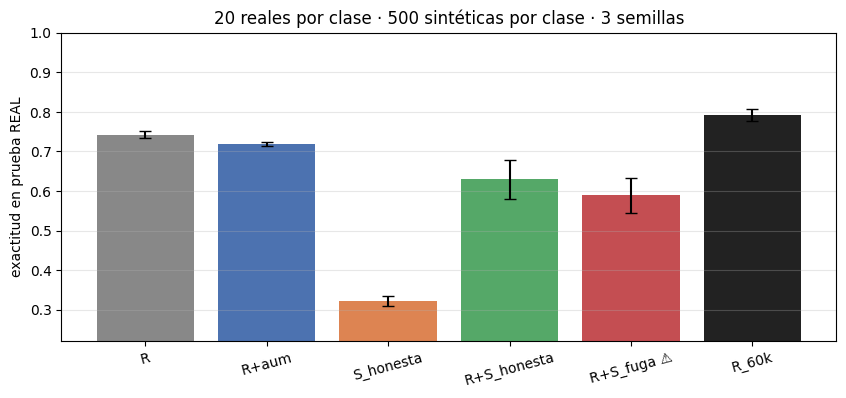

In [17]:
X_sh, Y_sh = muestras_cond(G_honesta, SINT_POR_CLASE, semilla=1)     # sintéticas honestas
X_sf, Y_sf = muestras_cond(G_completo, SINT_POR_CLASE, semilla=1)    # sintéticas con fuga

CONDICIONES = {
    "R":            lambda: (X_lim, Y_lim, False),
    "R+aum":        lambda: (X_lim, Y_lim, True),
    "S_honesta":    lambda: (X_sh, Y_sh, False),
    "R+S_honesta":  lambda: (torch.cat([X_lim, X_sh]), torch.cat([Y_lim, Y_sh]), False),
    "R+S_fuga ⚠️":  lambda: (torch.cat([X_lim, X_sf]), torch.cat([Y_lim, Y_sf]), False),
    "R_60k":        lambda: (X_tr, Y_tr, False),
}
filas, preds = [], {}
for nombre, datos in CONDICIONES.items():
    x, y, aum = datos()
    for s in SEMILLAS:
        acc, pred = entrenar_clasificador(x, y, aumento=aum, semilla=s)
        filas.append(dict(condicion=nombre, semilla=s, exactitud=acc, n_imagenes=len(x))); preds[(nombre, s)] = pred
    print(f"{nombre:<14s} n={len(x):>6}  exactitud = {np.mean([f['exactitud'] for f in filas if f['condicion'] == nombre]):.3f}")

res_aumento = pd.DataFrame(filas)
resumen_aum = res_aumento.groupby("condicion", sort=False).exactitud.agg(["mean", "std"]).round(4)
display(resumen_aum)
res_aumento.to_csv(f"aumento_sintetico_N{N_POR_CLASE}.csv", index=False)

plt.figure(figsize=(10, 4))
colores = ["#888", "#4c72b0", "#dd8452", "#55a868", "#c44e52", "#222"]
plt.bar(resumen_aum.index, resumen_aum["mean"], yerr=resumen_aum["std"], capsize=4, color=colores)
plt.ylim(max(0, resumen_aum["mean"].min() - 0.1), 1); plt.ylabel("exactitud en prueba REAL")
plt.title(f"{N_POR_CLASE} reales por clase · {SINT_POR_CLASE} sintéticas por clase · {len(SEMILLAS)} semillas")
plt.xticks(rotation=15); plt.grid(axis="y", alpha=.3); plt.savefig(f"aumento_sintetico_N{N_POR_CLASE}.png", dpi=110); plt.show()

In [18]:
# ¿En qué clases ayudaron (o dañaron) las sintéticas honestas? Diferencia de exactitud por clase vs. "R"
def acc_por_clase(nombre):
    return np.mean([[(preds[(nombre, s)][Y_te == c] == c).float().mean().item() for c in range(N_CLASES)] for s in SEMILLAS], axis=0)
dif = pd.DataFrame({"clase": CLASES,
                    "R": acc_por_clase("R"),
                    "Δ R+aum": acc_por_clase("R+aum") - acc_por_clase("R"),
                    "Δ R+S_honesta": acc_por_clase("R+S_honesta") - acc_por_clase("R")})
display(dif.round(3))

,clase,R,Δ R+aum,Δ R+S_honesta
0,camiseta,0.787,-0.104,-0.066
1,pantalón,0.879,0.005,-0.048
2,suéter,0.517,-0.013,-0.044
3,vestido,0.780,-0.116,-0.314
4,abrigo,0.520,-0.042,-0.090
5,sandalia,0.904,0.020,-0.178
6,camisa,0.386,0.104,-0.254
7,tenis,0.886,-0.093,-0.075
8,bolsa,0.889,0.022,-0.101
9,botín,0.871,-0.007,0.043


Ordena las condiciones por exactitud.

R = 0.787

R_ = 0.782

R+aum = 0.721

R+S_honesta = 0.675

R+S_fuga = 0.666

S_honesta = 0.443

¿Ayudó la cGAN honesta frente a `R`? ¿Y frente a `R+aum`? Responde con **media ± desviación** y discute si la diferencia es mayor que la variación entre semillas.

Para el primer caso la cGAN honesta no mejoro frente a R y la disminución es considerable respecto a la variación observada entre semillas. Frente a R+aum tampoco ayudo aunquela diferencia fue cercana a la division estandar en este caso la diferencia es menos contundente al considerar la variación entre semillas.

Explica con tus palabras por qué `R+S_fuga` **no** es un resultado válido aunque dé la mejor exactitud. ¿En qué situación real se cometería este error sin darse cuenta?

R+S_fuga no es válido porque existe una fuga de información. Su exactitud puede parecer mejor, pero no demuestra que el modelo realmente pueda generalizar a imágenes nuevas que nunca ha visto.

Se cometería un error si en un modelo para detectar enfermedades mediante radiografías la GAN se entrena con todas las radiografías disponibles y después utilizar imágenes sintéticas para entrenar un clasificador, aunque algunas radiografías pertenecieran al conjunto de prueba.


¿Qué te dice `S_honesta` (TSTR) sobre la calidad de las sintéticas?

Nos dice que nos da 44% de información útil para aprender algunas características de las clases, pero no son suficientemente buenas para sustituir a las imágenes reales. Ya que por si sola no son tan utiles para entrenar un clasificador.

¿En qué clases la cGAN honesta ayudó o dañó más (tabla por clase)?

Ayudo a pantalon y botin. Y daño mas a camiseta, vestido, tenis y camisa

## Parte D

Prof asigna un equipo variación, la ejecuta (vuelve a correr la Parte C con el cambio) y la presenta en 2 minutos en clase + pregunta:

| Equipo | Variación | Pregunta |
|---|---|---|
| 1 | `N_POR_CLASE = 20` | ¿Con aún menos datos las sintéticas ayudan más o menos? |
| 2 | `N_POR_CLASE = 200` | ¿A partir de cuántos datos reales deja de valer la pena? |
| 3 | `SINT_POR_CLASE = 50` y `= 2000` | ¿Más sintéticas = mejor? ¿Hay saturación? |
| 4 | cGAN honesta sin aumento diferenciable | ¿Cuánto importa estabilizar la cGAN para que las sintéticas sirvan? |
| 5 | Combinar `R+aum` **y** sintéticas honestas | ¿Son complementarias las dos formas de aumento? |
| 6 | Filtrar sintéticas: conservar solo las que el juez clasifica con confianza > 0.9 en su clase | ¿Filtrar por calidad ayuda? (cuidado: ¿el juez vio datos que no debería?) |

Se cambio el N_POR_CLASE=20, y ayuda mucho menos al tener solo 20 imagenes el discriminador si o si aprende completamente las 20 imagenes




# Parte E
Ejecuta con tus datos reales, compara 1 variación y grafica 16 imagenes generas por cGAN y por Aumentación

In [19]:
import os, zipfile, tarfile, shutil, subprocess
from pathlib import Path

RUTA_ZIP = "/content/train_images.zip"
CARPETA  = "/content/datos_acero"

def tipo_real(ruta):
    with open(ruta, "rb") as f:
        cab = f.read(8)
    if cab.startswith(b"PK\x03\x04"):         return "zip"
    if cab.startswith(b"Rar!"):               return "rar"
    if cab.startswith(b"7z\xbc\xaf\x27\x1c"): return "7z"
    if cab.startswith(b"\x1f\x8b"):           return "gzip/tar.gz"
    if cab.lstrip().lower().startswith((b"<!doc", b"<html")): return "html"
    try:
        if tarfile.is_tarfile(ruta): return "tar"
    except Exception:
        pass
    return f"desconocido (primeros bytes: {cab!r})"

def hay_imagenes(carpeta):
    return any(p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"} for p in Path(carpeta).rglob("*"))

if os.path.isdir(CARPETA) and hay_imagenes(CARPETA):
    print("Las imágenes ya estaban descomprimidas en", CARPETA)
else:
    if not os.path.exists(RUTA_ZIP):
        raise FileNotFoundError(f"No existe {RUTA_ZIP}. Revisa el nombre en el panel de archivos de la izquierda.")
    tam_mb = os.path.getsize(RUTA_ZIP) / 1e6
    tipo = tipo_real(RUTA_ZIP)
    print(f"Archivo: {RUTA_ZIP} · {tam_mb:,.1f} MB · formato real: {tipo}")
    shutil.rmtree(CARPETA, ignore_errors=True); os.makedirs(CARPETA)

    if tipo == "zip":
        if not zipfile.is_zipfile(RUTA_ZIP):
            raise RuntimeError(
                "El archivo EMPIEZA como zip pero está CORTADO: la subida a Colab no terminó o se interrumpió.\n"
                f"Pesa {tam_mb:,.1f} MB; compáralo con el tamaño del zip en tu computadora.\n"
                "Solución: espera a que termine la subida (círculo de progreso abajo a la izquierda) o súbelo "
                "a Google Drive y usa la celda E.0b.")
        with zipfile.ZipFile(RUTA_ZIP) as z:
            malos = z.testzip()
            if malos: print("⚠️ Archivo dañado dentro del zip:", malos)
            z.extractall(CARPETA)
    elif tipo in ("tar", "gzip/tar.gz"):
        shutil.unpack_archive(RUTA_ZIP, CARPETA, format="gztar" if tipo.startswith("gzip") else "tar")
    elif tipo in ("rar", "7z"):
        subprocess.run("apt-get -qq install -y p7zip-full p7zip-rar > /dev/null", shell=True)
        r = subprocess.run(["7z", "x", "-y", RUTA_ZIP, f"-o{CARPETA}"], capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError("7z no pudo descomprimir:\n" + r.stderr[-1500:])
    elif tipo == "html":
        raise RuntimeError("El archivo es una PÁGINA WEB (HTML), no las imágenes: se descargó mal de Kaggle. "
                           "Descárgalo de nuevo (o usa la celda E.0c con la API de Kaggle).")
    else:
        raise RuntimeError(f"Formato no reconocido: {tipo}. Vuelve a comprimir la carpeta como .zip y súbela de nuevo.")

n = sum(1 for p in Path(CARPETA).rglob("*") if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp"})
print(f"✅ {n:,} imágenes listas en {CARPETA}")

Archivo: /content/train_images.zip · 1,248.4 MB · formato real: zip
✅ 12,568 imágenes listas en /content/datos_acero


In [21]:

import zipfile, re
from pathlib import Path
from collections import Counter
from PIL import Image
import pandas as pd
import numpy as np

RUTA_CSV  = "/content/train.csv"
CARPETA   = "datos_acero"
LADO      = 32           # la arquitectura DCGAN del notebook trabaja a 32x32
PRUEBA    = 0.30         # fracción para el test real
MIN_IMGS  = 10           # se descartan clases con menos imágenes que esto
MAX_POR_CLASE = 500      # tope por clase: balancea y acelera la lectura (Severstal tiene ~12 000 imágenes)
INCLUIR_SIN_DEFECTO = True   # con CSV: las imágenes que no aparecen en él se toman como clase 'sin_defecto'
N_GRUPOS  = 4            # sin CSV: número de pseudo-clases de KMeans
SEMILLA_DATOS = 0




EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
rutas = sorted(p for p in Path(CARPETA).rglob("*")
               if p.suffix.lower() in EXT and "__MACOSX" not in p.parts and not p.name.startswith("."))
if not rutas:
    raise FileNotFoundError(f"No encontré imágenes dentro de {RUTA_ZIP}")
por_nombre = {p.name: p for p in rutas}
print("Imágenes encontradas:", len(rutas))

csvs = [Path(RUTA_CSV)] if os.path.exists(RUTA_CSV) else []
csvs += [p for p in Path(CARPETA).rglob("*.csv") if "__MACOSX" not in p.parts and "sample" not in p.name.lower()]

def leer_csv_severstal(csv):
    """Admite los dos formatos de Severstal:
       nuevo:  ImageId, ClassId, EncodedPixels
       viejo:  ImageId_ClassId ('0002cc93b.jpg_1'), EncodedPixels (vacío si no hay defecto)"""
    df = pd.read_csv(csv)
    if "ImageId_ClassId" in df.columns:
        df[["ImageId", "ClassId"]] = df["ImageId_ClassId"].str.rsplit("_", n=1, expand=True)
    df = df.dropna(subset=["EncodedPixels"])
    df["ClassId"] = df["ClassId"].astype(int)
    return df[["ImageId", "ClassId", "EncodedPixels"]]

def rle_a_mascara(rle, alto, ancho):
    """RLE de Severstal: píxeles numerados de arriba a abajo y luego de izquierda a derecha, empezando en 1."""
    s = np.asarray(str(rle).split(), dtype=np.int64)
    m = np.zeros(alto * ancho, dtype=np.uint8)
    for ini, lon in zip(s[0::2] - 1, s[1::2]):
        m[ini:ini + lon] = 1
    return m.reshape(ancho, alto).T

def recorte_cuadrado(im, centro_x=None):
    """Las láminas miden 1600x256: aplastarlas a 32x32 deforma el defecto.
    Se recorta un cuadrado de alto x alto (centrado en el defecto si se conoce; si no, el de más textura)."""
    a = np.asarray(im, dtype=np.uint8); h, w = a.shape
    if w <= h:
        return a
    if centro_x is None:
        inicios = np.linspace(0, w - h, max(2, w // h)).astype(int)
        x0 = max(inicios, key=lambda i: a[:, i:i + h].std())
    else:
        x0 = int(np.clip(centro_x - h // 2, 0, w - h))
    return a[:, x0:x0 + h]

def leer(p, rle=None):
    im = Image.open(p).convert("L")
    cx = None
    if rle is not None:
        m = rle_a_mascara(rle, im.height, im.width)
        cols = np.nonzero(m.sum(0))[0]
        cx = int(np.median(cols)) if len(cols) else None
    a = recorte_cuadrado(im, cx)
    return np.asarray(Image.fromarray(a).resize((LADO, LADO), Image.BICUBIC), dtype=np.uint8)

rng = np.random.default_rng(SEMILLA_DATOS)

if csvs:
    df = leer_csv_severstal(csvs[0])
    print(f"Usando etiquetas de: {csvs[0]}")
    df = df[df.ImageId.isin(por_nombre)]
    if df.empty:
        raise ValueError("El CSV no coincide con ninguna imagen del zip (¿son las imágenes de test? Esas no tienen etiqueta).")
    # Una imagen puede tener varios defectos: se queda la clase con MAYOR área
    df["area"] = df.EncodedPixels.map(lambda r: np.asarray(str(r).split(), dtype=np.int64)[1::2].sum())
    df = df.sort_values("area", ascending=False).drop_duplicates("ImageId")
    registros = [(r.ImageId, f"defecto_{r.ClassId}", r.EncodedPixels) for r in df.itertuples()]
    if INCLUIR_SIN_DEFECTO:
        sin = sorted(set(por_nombre) - set(df.ImageId))
        registros += [(n, "sin_defecto", None) for n in sin]
    # tope por clase (aleatorio) antes de leer las imágenes
    por_clase = {}
    for reg in registros: por_clase.setdefault(reg[1], []).append(reg)
    pares = []
    for c, regs in por_clase.items():
        sel = rng.permutation(len(regs))[:MAX_POR_CLASE]
        pares += [regs[i] for i in sel]
    print("Imágenes por clase en el CSV:", {c: len(v) for c, v in sorted(por_clase.items())})
    print("Leyendo y recortando imágenes...")
    arr = np.stack([leer(por_nombre[n], rle) for n, _, rle in pares])
    etiquetas = [c for _, c, _ in pares]
else:
    print("⚠️ No hay train.csv: se crean", N_GRUPOS, "pseudo-clases con KMeans (no son tipos de defecto reales).")
    from sklearn.decomposition import PCA
    from sklearn.cluster import KMeans
    sel = rng.permutation(len(rutas))[:MAX_POR_CLASE * N_GRUPOS * 2]
    arr = np.stack([leer(rutas[i]) for i in sel])
    feats = PCA(n_components=min(50, len(arr) - 1), random_state=0).fit_transform(arr.reshape(len(arr), -1) / 255.0)
    grupos = KMeans(N_GRUPOS, n_init=10, random_state=0).fit_predict(feats)
    keep = np.concatenate([rng.permutation(np.where(grupos == g)[0])[:MAX_POR_CLASE] for g in range(N_GRUPOS)])
    arr, etiquetas = arr[keep], [f"grupo_{grupos[i]}" for i in keep]

conteo = Counter(etiquetas)
CLASES = sorted(c for c in conteo if conteo[c] >= MIN_IMGS)
mask = np.array([c in CLASES for c in etiquetas])
arr = arr[mask]; etiquetas = [c for c, k in zip(etiquetas, mask) if k]
N_CLASES, CANALES = len(CLASES), 1
if N_CLASES < 2:
    raise ValueError(f"Solo quedó {N_CLASES} clase; baja MIN_IMGS o revisa el CSV.")
print("Clases usadas:", {c: conteo[c] for c in CLASES})

X_all = torch.as_tensor(arr).unsqueeze(1).float().div(255).mul(2).sub(1)
Y_all = torch.as_tensor([CLASES.index(c) for c in etiquetas]).long()
print("Tensor:", tuple(X_all.shape), "rango", (round(X_all.min().item(), 2), round(X_all.max().item(), 2)))


Imágenes encontradas: 12568
Usando etiquetas de: /content/train.csv
Imágenes por clase en el CSV: {'defecto_1': 829, 'defecto_2': 225, 'defecto_3': 4894, 'defecto_4': 718, 'sin_defecto': 5902}
Leyendo y recortando imágenes...
Clases usadas: {'defecto_1': 500, 'defecto_2': 225, 'defecto_3': 500, 'defecto_4': 500, 'sin_defecto': 500}
Tensor: (2225, 1, 32, 32) rango (-1.0, 1.0)


,clase,train,test
0,defecto_1,350,150
1,defecto_2,157,68
2,defecto_3,350,150
3,defecto_4,350,150
4,sin_defecto,350,150


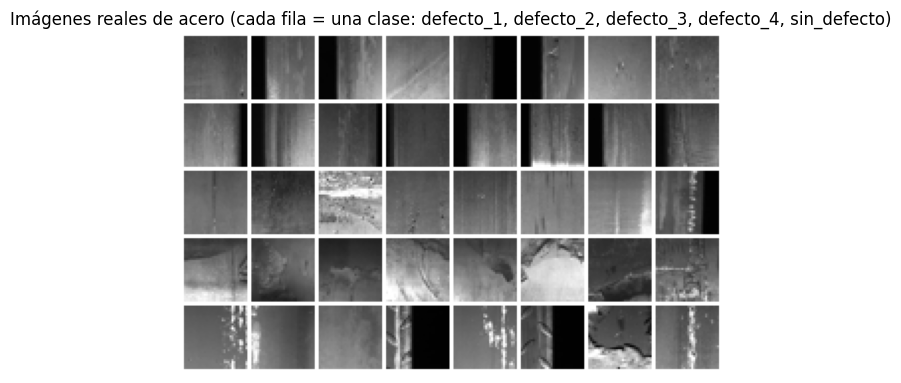

In [22]:
def particion_estratificada(y, prueba=0.3, semilla=0):
    rng = np.random.default_rng(semilla); i_tr, i_te = [], []
    for c in range(N_CLASES):
        idx = rng.permutation(np.where(y.numpy() == c)[0])
        n_te = max(1, int(round(len(idx) * prueba)))
        i_te += idx[:n_te].tolist(); i_tr += idx[n_te:].tolist()
    return torch.tensor(i_tr), torch.tensor(i_te)

i_tr, i_te = particion_estratificada(Y_all, PRUEBA, semilla=0)
X_tr, Y_tr = X_all[i_tr].to(DEVICE), Y_all[i_tr].to(DEVICE)
X_te, Y_te = X_all[i_te].to(DEVICE), Y_all[i_te].to(DEVICE)

display(pd.DataFrame({"clase": CLASES,
                      "train": [(Y_tr == c).sum().item() for c in range(N_CLASES)],
                      "test":  [(Y_te == c).sum().item() for c in range(N_CLASES)]}))

ej = torch.cat([X_tr[Y_tr == c][:8] for c in range(N_CLASES)])
mostrar_grid(ej, "Imágenes reales de acero (cada fila = una clase: " + ", ".join(CLASES) + ")", nrow=8, tam=(7, 7))

In [23]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

def lotes(x, y, batch, mezclar=True):
    idx = torch.randperm(len(x), device=x.device) if mezclar else torch.arange(len(x), device=x.device)
    for i in range(0, len(x) - batch + 1, batch):
        j = idx[i:i + batch]
        yield x[j], y[j]

class Juez(nn.Module):
    """CNN pequeña entrenada con datos REALES."""
    def __init__(self, canales=1, n_clases=10):
        super().__init__()
        self.cuerpo = nn.Sequential(
            nn.Conv2d(canales, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.AdaptiveAvgPool2d(1),
            nn.Flatten())
        self.cabeza = nn.Linear(128, n_clases)
    def forward(self, x): return self.cabeza(self.cuerpo(x))
    @torch.no_grad()
    def caracteristicas(self, x, lote=500):
        self.eval(); return torch.cat([self.cuerpo(x[i:i + lote]) for i in range(0, len(x), lote)])
    @torch.no_grad()
    def probabilidades(self, x, lote=500):
        self.eval(); return torch.cat([F.softmax(self(x[i:i + lote]), 1) for i in range(0, len(x), lote)])

def entrenar_juez(x, y, x_te, y_te, epocas=3, batch=256, aumento=False, semilla=0, verbose=True):
    fijar_semilla(semilla)
    m = Juez(x.shape[1], int(y.max()) + 1).to(DEVICE)
    opt = torch.optim.Adam(m.parameters(), 1e-3)
    for ep in range(epocas):
        m.train()
        for xb, yb in lotes(x, y, min(batch, len(x))):
            if aumento:
                xb = torch.roll(xb, shifts=(int(np.random.randint(-2, 3)), int(np.random.randint(-2, 3))), dims=(2, 3))
                if np.random.rand() < 0.5: xb = xb.flip(3)
            loss = F.cross_entropy(m(xb), yb)
            opt.zero_grad(); loss.backward(); opt.step()
    acc = (m.probabilidades(x_te).argmax(1) == y_te).float().mean().item()
    if verbose: print(f"Juez: exactitud en prueba real = {acc:.3f}")
    return m, acc

juez, acc_juez = entrenar_juez(X_tr, Y_tr, X_te, Y_te, epocas=40, batch=64, aumento=True)
torch.save(juez.state_dict(), "juez_acero.pt")

Juez: exactitud en prueba real = 0.656


Datos limitados: 250 imágenes reales (50 por clase)
[cGAN-acero-250] it   500/3000  loss_D 1.195  loss_G 0.814  acc_cond 0.305  FID-d 51.6  (12 s)
[cGAN-acero-250] it  1000/3000  loss_D 1.109  loss_G 1.427  acc_cond 0.276  FID-d 59.9  (25 s)
[cGAN-acero-250] it  1500/3000  loss_D 1.175  loss_G 1.046  acc_cond 0.341  FID-d 28.5  (37 s)
[cGAN-acero-250] it  2000/3000  loss_D 1.265  loss_G 1.299  acc_cond 0.482  FID-d 16.6  (50 s)
[cGAN-acero-250] it  2500/3000  loss_D 1.397  loss_G 0.957  acc_cond 0.525  FID-d 15.3  (62 s)
[cGAN-acero-250] it  3000/3000  loss_D 1.318  loss_G 1.224  acc_cond 0.548  FID-d 16.7  (74 s)


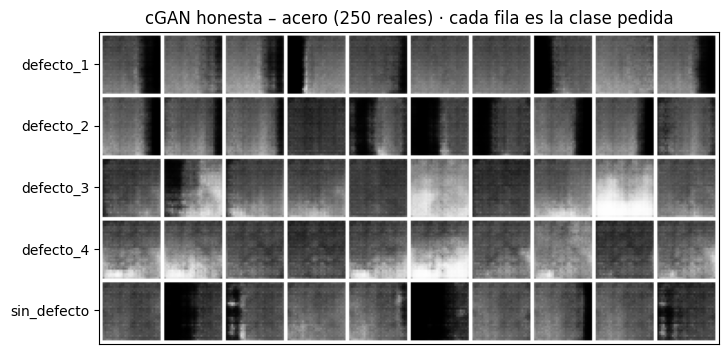

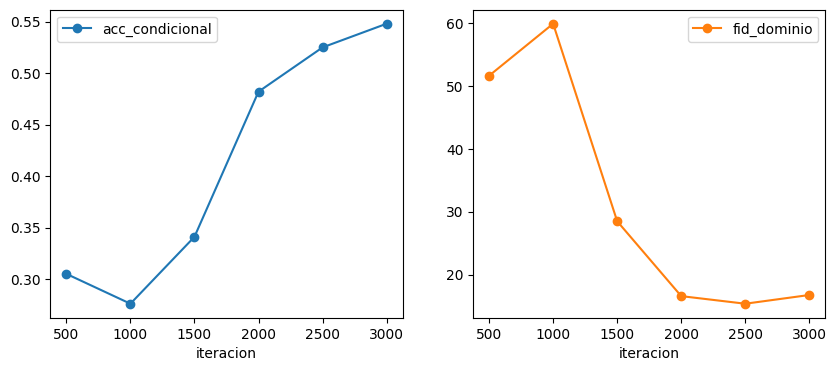

In [24]:
min_train = min((Y_tr == c).sum().item() for c in range(N_CLASES))
N_POR_CLASE    = min(50, min_train)   # reales por clase disponibles para entrenar
SINT_POR_CLASE = 500                  # sintéticas por clase
PASOS_CLF      = 800                  # mismo presupuesto de pasos para todos los clasificadores
SEMILLAS       = [0, 1, 2]
ITER_LIMITADO  = 3000

X_lim, Y_lim = subconjunto_limitado(N_POR_CLASE)
print(f"Datos limitados: {len(X_lim)} imágenes reales ({N_POR_CLASE} por clase)")

G_honesta, h_honesta = entrenar_cgan(X_lim, Y_lim, ITER_LIMITADO, batch=64, ruido_instancia=0.1, aumento_D=True,
                                     nombre=f"cGAN-acero-{len(X_lim)}")
rejilla_por_clase(G_honesta, f"cGAN honesta – acero ({len(X_lim)} reales) · cada fila es la clase pedida")
h_honesta.plot(x="iteracion", y=["acc_condicional", "fid_dominio"], subplots=True, marker="o", figsize=(10, 4), layout=(1, 2)); plt.show()

X_sh, Y_sh = muestras_cond(G_honesta, SINT_POR_CLASE, semilla=1)

[cGAN-acero-sin-aumD] it   500/3000  loss_D 1.007  loss_G 2.278  acc_cond 0.200  FID-d 118.5  (12 s)
[cGAN-acero-sin-aumD] it  1000/3000  loss_D 0.834  loss_G 2.271  acc_cond 0.151  FID-d 134.3  (24 s)
[cGAN-acero-sin-aumD] it  1500/3000  loss_D 0.562  loss_G 3.416  acc_cond 0.330  FID-d 55.8  (37 s)
[cGAN-acero-sin-aumD] it  2000/3000  loss_D 0.696  loss_G 2.285  acc_cond 0.399  FID-d 43.6  (49 s)
[cGAN-acero-sin-aumD] it  2500/3000  loss_D 0.409  loss_G 3.825  acc_cond 0.295  FID-d 51.2  (62 s)
[cGAN-acero-sin-aumD] it  3000/3000  loss_D 0.411  loss_G 3.901  acc_cond 0.391  FID-d 37.5  (74 s)


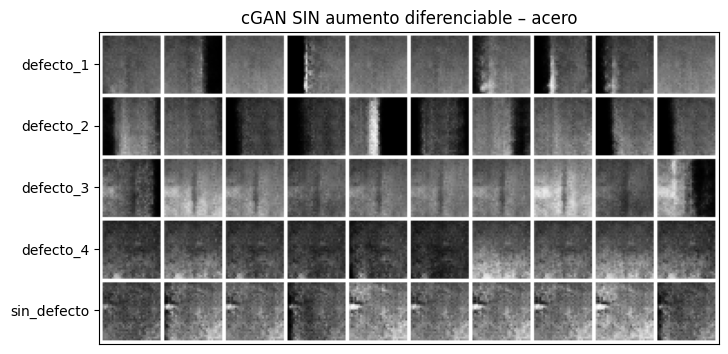

,modelo,acc_condicional,fid_dominio,D_x,D_Gz
5,con aumento_D,0.548,16.74,0.432112,0.377948
5,sin aumento_D,0.391,37.53,0.929984,0.057611


In [25]:

VARIACION = "sin_aumento_D"

G_var = None
if VARIACION == "sin_aumento_D":
    G_var, h_var = entrenar_cgan(X_lim, Y_lim, ITER_LIMITADO, batch=64, ruido_instancia=0.0, aumento_D=False,
                                 nombre="cGAN-acero-sin-aumD")
    rejilla_por_clase(G_var, "cGAN SIN aumento diferenciable – acero")
    comp = pd.concat([h_honesta.iloc[[-1]].assign(modelo="con aumento_D"), h_var.iloc[[-1]].assign(modelo="sin aumento_D")])
    display(comp[["modelo", "acc_condicional", "fid_dominio", "D_x", "D_Gz"]])
    X_sv, Y_sv = muestras_cond(G_var, SINT_POR_CLASE, semilla=1)
    VAR_CONDS = {"S_sin_aumD":   lambda: (X_sv, Y_sv, False),
                 "R+S_sin_aumD": lambda: (torch.cat([X_lim, X_sv]), torch.cat([Y_lim, Y_sv]), False)}
elif VARIACION == "combinar":
    VAR_CONDS = {"R+aum+S_honesta": lambda: (torch.cat([X_lim, X_sh]), torch.cat([Y_lim, Y_sh]), True)}
elif VARIACION == "filtrar":
    conf = juez.probabilidades(X_sh)[torch.arange(len(Y_sh), device=DEVICE), Y_sh]
    keep = conf > 0.9
    print(f"Se conservan {keep.sum().item()} de {len(keep)} sintéticas;",
          {CLASES[c]: int((Y_sh[keep] == c).sum()) for c in range(N_CLASES)})
    X_sfil, Y_sfil = X_sh[keep], Y_sh[keep]
    VAR_CONDS = {"R+S_filtradas": lambda: (torch.cat([X_lim, X_sfil]), torch.cat([Y_lim, Y_sfil]), False)}
else:
    raise ValueError(VARIACION)

R                n=   250  exactitud = 0.610 ± 0.047
R+aum            n=   250  exactitud = 0.595 ± 0.008
S_honesta        n=  2500  exactitud = 0.323 ± 0.033
R+S_honesta      n=  2750  exactitud = 0.497 ± 0.077
S_sin_aumD       n=  2500  exactitud = 0.258 ± 0.006
R+S_sin_aumD     n=  2750  exactitud = 0.566 ± 0.021
R_completo       n=  1557  exactitud = 0.710 ± 0.016


,mean,std
condicion,,
R_completo,0.7096,0.0156
R,0.6103,0.0465
R+aum,0.5953,0.0082
R+S_sin_aumD,0.5659,0.0211
R+S_honesta,0.4965,0.0773
S_honesta,0.3234,0.0329
S_sin_aumD,0.2580,0.0062


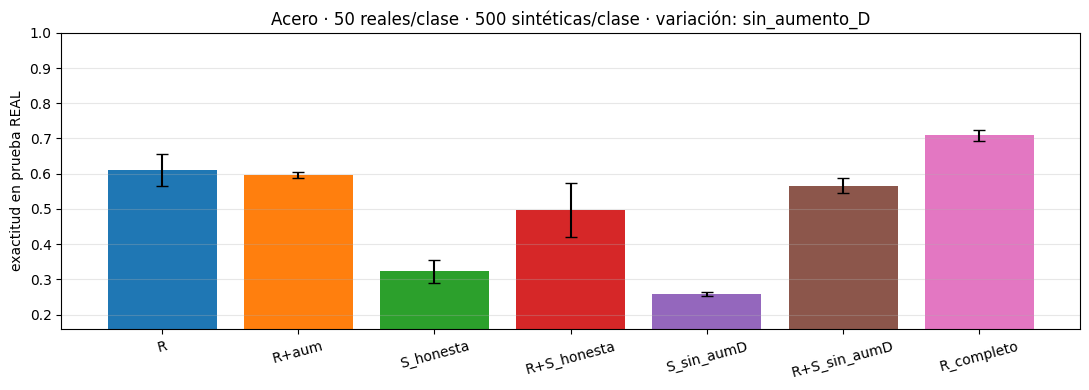

,clase,R,Δ R+aum,Δ S_honesta,Δ R+S_honesta,Δ S_sin_aumD,Δ R+S_sin_aumD
0,defecto_1,0.449,0.047,0.318,0.031,0.529,0.149
1,defecto_2,0.843,-0.152,-0.485,-0.015,-0.794,-0.221
2,defecto_3,0.733,0.036,-0.600,-0.309,-0.667,-0.278
3,defecto_4,0.731,-0.096,-0.522,-0.213,-0.649,0.153
4,sin_defecto,0.422,0.016,-0.253,-0.009,-0.422,-0.122


In [26]:
CONDICIONES = {
    "R":           lambda: (X_lim, Y_lim, False),
    "R+aum":       lambda: (X_lim, Y_lim, True),
    "S_honesta":   lambda: (X_sh, Y_sh, False),
    "R+S_honesta": lambda: (torch.cat([X_lim, X_sh]), torch.cat([Y_lim, Y_sh]), False),
    **VAR_CONDS,
    "R_completo":  lambda: (X_tr, Y_tr, False),
}
filas, preds = [], {}
for nombre, datos in CONDICIONES.items():
    x, y, aum = datos()
    for s in SEMILLAS:
        acc, pred = entrenar_clasificador(x, y, pasos=PASOS_CLF, aumento=aum, semilla=s)
        filas.append(dict(condicion=nombre, semilla=s, exactitud=acc, n_imagenes=len(x))); preds[(nombre, s)] = pred
    accs = [f["exactitud"] for f in filas if f["condicion"] == nombre]
    print(f"{nombre:<16s} n={len(x):>6}  exactitud = {np.mean(accs):.3f} ± {np.std(accs, ddof=1):.3f}")

res_acero = pd.DataFrame(filas)
resumen_acero = res_acero.groupby("condicion", sort=False).exactitud.agg(["mean", "std"]).round(4)
display(resumen_acero.sort_values("mean", ascending=False))
res_acero.to_csv(f"acero_aumento_N{N_POR_CLASE}_{VARIACION}.csv", index=False)

plt.figure(figsize=(11, 4))
plt.bar(resumen_acero.index, resumen_acero["mean"], yerr=resumen_acero["std"], capsize=4,
        color=plt.cm.tab10(np.arange(len(resumen_acero))))
plt.ylim(max(0, resumen_acero["mean"].min() - 0.1), 1); plt.ylabel("exactitud en prueba REAL")
plt.title(f"Acero · {N_POR_CLASE} reales/clase · {SINT_POR_CLASE} sintéticas/clase · variación: {VARIACION}")
plt.xticks(rotation=15); plt.grid(axis="y", alpha=.3); plt.tight_layout()
plt.savefig(f"acero_aumento_{VARIACION}.png", dpi=110); plt.show()

def acc_por_clase(nombre):
    return np.mean([[(preds[(nombre, s)][Y_te == c] == c).float().mean().item() for c in range(N_CLASES)] for s in SEMILLAS], axis=0)
tabla = {"clase": CLASES, "R": acc_por_clase("R")}
for n in CONDICIONES:
    if n not in ("R", "R_completo"):
        tabla[f"Δ {n}"] = acc_por_clase(n) - acc_por_clase("R")
display(pd.DataFrame(tabla).round(3))

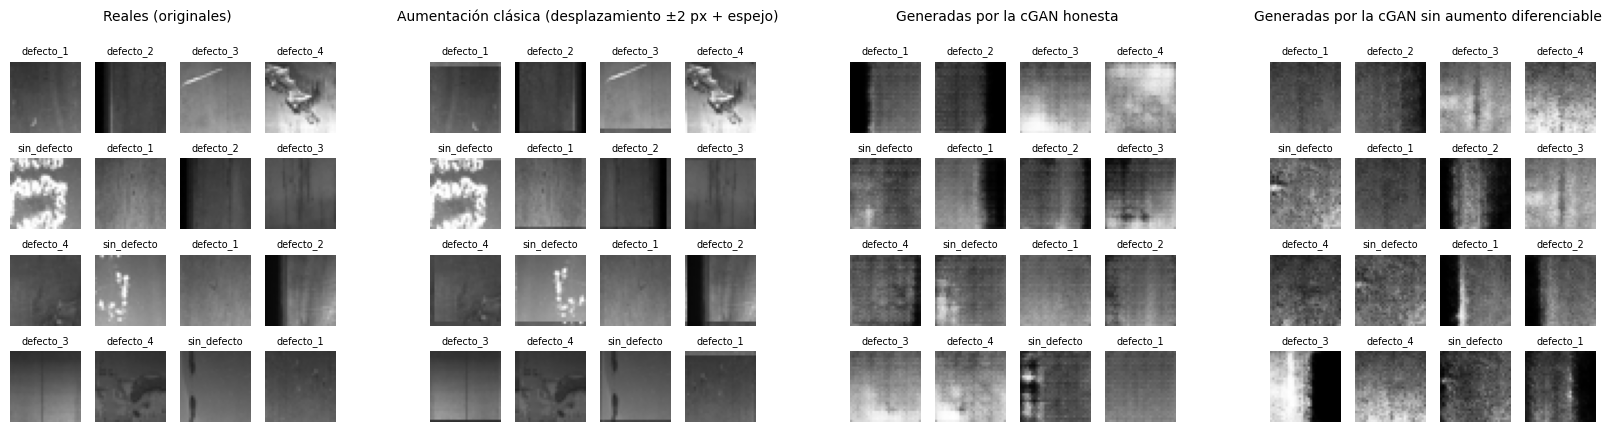

In [27]:
def aumento_clasico_individual(x, semilla=0):
    rng = np.random.default_rng(semilla); out = []
    for xi in x:
        dx, dy = rng.integers(-2, 3, size=2)
        xi = torch.roll(xi, shifts=(int(dx), int(dy)), dims=(1, 2))
        out.append(xi.flip(2) if rng.random() < 0.5 else xi)
    return torch.stack(out)

y16 = (torch.arange(16) % N_CLASES).to(DEVICE)
g = torch.Generator(device="cpu").manual_seed(0)
idx16 = torch.stack([torch.nonzero(Y_lim.cpu() == int(c)).view(-1)[torch.randint(0, N_POR_CLASE, (1,), generator=g)].squeeze() for c in y16.cpu()])
x_real16 = X_lim[idx16.to(DEVICE)]
x_aum16  = aumento_clasico_individual(x_real16, semilla=0)
with torch.no_grad():
    G_honesta.eval(); x_gan16 = G_honesta(torch.randn(16, 100, device=DEVICE, generator=torch.Generator(device=DEVICE).manual_seed(3)), y16); G_honesta.train()

paneles = [("Reales (originales)", x_real16), ("Aumentación clásica (desplazamiento ±2 px + espejo)", x_aum16),
           ("Generadas por la cGAN honesta", x_gan16)]
if G_var is not None:
    with torch.no_grad():
        G_var.eval(); x_var16 = G_var(torch.randn(16, 100, device=DEVICE, generator=torch.Generator(device=DEVICE).manual_seed(3)), y16); G_var.train()
    paneles.append(("Generadas por la cGAN sin aumento diferenciable", x_var16))

fig = plt.figure(figsize=(4.2 * len(paneles), 4.8))
sub = fig.subfigures(1, len(paneles))
for sf, (tit, x) in zip(np.atleast_1d(sub), paneles):
    axs = sf.subplots(4, 4)
    for k, ax in enumerate(axs.flat):
        ax.imshow(x[k, 0].detach().cpu().numpy(), cmap="gray", vmin=-1, vmax=1)
        ax.set_title(CLASES[int(y16[k])], fontsize=7); ax.axis("off")
    sf.suptitle(tit, fontsize=10)
plt.savefig("acero_16_cgan_vs_aumentacion.png", dpi=120, bbox_inches="tight"); plt.show()